# 04. Random Forest

Mục tiêu là chọn cấu hình Random Forest bằng 5 fold chung trong Train, sau đó đánh giá mô hình đã chọn trên Validation.

| Phần | Dữ liệu sử dụng | Đầu ra |
|---|---|---|
| Chạy thử | Phần học và phần chấm của fold 1 | Kiểm tra luồng từ pipeline đến metric |
| Chọn cấu hình | Cùng 5 fold trong Train | Bảng điểm từng fold và cấu hình được chọn |
| Đánh giá và phân tích | Fit trên toàn Train, chấm trên Validation | Điểm, ma trận nhầm lẫn và phân tích đặc trưng |
| Bàn giao | Pipeline đã fit | File mô hình, thông tin lượt chạy và bảng kết quả |

Test được giữ cho bước đánh giá cuối của nhóm. Các bảng và hình trong notebook này mô tả **Validation**.

## 1. Đọc dữ liệu và kiểm tra bộ chia

Notebook dùng `data/raw/data.csv` và `data/splits/splits.json` đã có trong repo. Chỉ số trong file bộ chia là vị trí dòng trong CSV gốc, tính từ 0.

In [1]:
import hashlib
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

# Tìm thư mục gốc để import các hàm dùng chung khi kernel mở từ thư mục notebook.
here = Path.cwd().resolve()
root = next(
    (folder for folder in (here, *here.parents)
     if (folder / "common/preprocessing.py").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Mở thư mục student-dropout-prediction trong VS Code.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from common.metrics import confusion_frame, evaluate, per_class_frame, summary_frame
from common.preprocessing import FEATURE_COLUMNS, LABELS, TARGET, make_preprocessor

data_path = root / "data/raw/data.csv"
split_path = root / "data/splits/splits.json"


def text_sha256(path):
    # Hai bản clone chỉ khác cách xuống dòng sẽ có cùng mã nhận diện file.
    return hashlib.sha256(path.read_bytes().replace(b"\r\n", b"\n")).hexdigest()


data = pd.read_csv(data_path, sep=";", encoding="utf-8-sig")
data.columns = data.columns.str.strip()
split = json.loads(split_path.read_text(encoding="utf-8"))
data_hash = text_sha256(data_path)
split_hash = text_sha256(split_path)
if split["sha256"] != data_hash or split["n_rows"] != len(data):
    raise ValueError("CSV không khớp với bộ chia chung. Kiểm tra lại hai file đầu vào.")

train_rows = split["train"]
val_rows = split["validation"]
folds = split["folds"]
seed = split["seed"]

In [2]:
def row_set(indices, name):
    # Kiểm tra trước khi dùng iloc, vì chỉ số âm cũng có thể chọn nhầm dòng.
    if not indices or any(type(index) is not int or not 0 <= index < len(data)
                          for index in indices):
        raise ValueError(f"Chỉ số dòng không hợp lệ trong {name}.")
    unique = set(indices)
    if len(unique) != len(indices):
        raise ValueError(f"Có chỉ số dòng bị lặp trong {name}.")
    return unique


train_set = row_set(train_rows, "Train")
val_set = row_set(val_rows, "Validation")
# Dùng chỉ số Test để đối chiếu bộ chia. Phần huấn luyện và chấm bên dưới lấy Train/Validation.
test_set = row_set(split["test"], "Test")
if (len(train_set | val_set | test_set) != len(data)
        or len(train_set) + len(val_set) + len(test_set) != len(data)):
    raise ValueError("Ba tập phải tách rời và bao phủ các dòng của CSV.")

if len(folds) != 5:
    raise ValueError("Cần đúng 5 fold chung trong Train.")

scored_rows = set()
fold_sizes = []
for number, fold in enumerate(folds, start=1):
    fit_set = row_set(fold["train"], f"phần học fold {number}")
    score_set = row_set(fold["validation"], f"phần chấm fold {number}")
    if fit_set & score_set or (fit_set | score_set) != train_set:
        raise ValueError(f"Fold {number} phải chia Train thành hai phần tách rời.")
    if scored_rows & score_set:
        raise ValueError("Có dòng Train xuất hiện ở phần chấm của nhiều fold.")
    scored_rows.update(score_set)
    fold_sizes.append({"fold": number, "số mẫu học": len(fit_set), "số mẫu chấm": len(score_set)})
if scored_rows != train_set:
    raise ValueError("Mỗi dòng Train phải được dùng để chấm đúng một lượt CV.")

# Giữ thứ tự CSV của X và y để các chỉ số trên trỏ tới cùng sinh viên.
X = data.loc[:, list(FEATURE_COLUMNS)]
y = data[TARGET]
print(f"Train: {len(train_rows):,} mẫu | Validation: {len(val_rows):,} mẫu")
display(pd.DataFrame(fold_sizes).set_index("fold"))

Train: 3,096 mẫu | Validation: 664 mẫu


,số mẫu học,số mẫu chấm
fold,,
1,2476,620
2,2477,619
3,2477,619
4,2477,619
5,2477,619


## 2. Tạo pipeline và chạy thử fold 1

`preprocess` điền giá trị thiếu theo quy tắc chung và mã hóa cột phân loại. RF chia dữ liệu theo ngưỡng của từng đặc trưng, nên dùng `scale_numeric=False` để giữ thang đo gốc của cột số. Cột nhị phân vẫn giữ 0/1. Bước `model` học nhiều cây, sau đó kết hợp xác suất từ các cây để chọn một trong ba nhãn.

Giữ `max_features="sqrt"` và `bootstrap=True` theo mặc định của scikit-learn. `random_state=42` lấy từ file bộ chia của nhóm để có thể tái lập kết quả khi chạy cùng dữ liệu và phiên bản thư viện.

Lượt chạy thử lấy fold đầu tiên trong bộ chia chung vì chỉ cần một lượt để kiểm tra đường đi từ `fit()` đến `predict()` và hàm metric. Cấu hình chạy thử dùng 100 cây, độ sâu tối đa 10, tối thiểu 5 mẫu mỗi lá và `class_weight=None`. Đây là một tổ hợp có sẵn trong lưới bên dưới, với số cây thấp hơn và hai giới hạn kích thước cây để chạy kiểm tra nhanh.

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline


def make_rf_pipeline(config):
    # Trả về pipeline mới để mỗi cấu hình và mỗi fold tự fit từ đầu.
    forest = RandomForestClassifier(
        random_state=seed, max_features="sqrt", bootstrap=True, n_jobs=1, **config,
    )
    return Pipeline([
        ("preprocess", make_preprocessor(scale_numeric=False)),
        ("model", forest),
    ])


def score_fold(config, fold):
    model = make_rf_pipeline(config)
    fit_rows = fold["train"]
    score_rows = fold["validation"]
    model.fit(X.iloc[fit_rows], y.iloc[fit_rows])
    # X và y cùng lấy theo score_rows để metric so đúng nhãn của từng sinh viên.
    predicted = model.predict(X.iloc[score_rows])
    return evaluate(y.iloc[score_rows], predicted)


smoke_config = {
    "n_estimators": 100, "max_depth": 10, "min_samples_leaf": 5, "class_weight": None,
}
smoke_result = score_fold(smoke_config, folds[0])
display(summary_frame({"Kiểm tra fold 1": smoke_result}).round(4))

,accuracy,macro_f1,dropout_recall,dropout_precision,dropout_f2
model,,,,,
Kiểm tra fold 1,0.7258,0.5786,0.7588,0.6895,0.7438


## 3. Thử 16 cấu hình qua 5 fold trong Train

Lưới ban đầu lấy các giá trị mặc định của scikit-learn làm mốc đối chiếu và thêm một lựa chọn cho mỗi tham số. Hai mức trên mỗi trục cho **16 tổ hợp**. Chấm mỗi tổ hợp trên **5 fold chung của Train** cần **80 lượt fit** cho bước tuning. Các tài liệu dưới đây được đối chiếu sau lượt chạy để giải thích ý nghĩa và bối cảnh của từng mốc.

| Tham số | Giá trị thử | Vì sao chọn các giá trị này? |
|---|---|---|
| `n_estimators` | `100`, `200` | **100** là mặc định và làm mốc chi phí huấn luyện. **200** do em chọn để thử tăng gấp đôi số cây. So sánh hai mức cho biết mức thay đổi Macro-F1 khi rừng tổng hợp dự đoán từ nhiều cây hơn. [Tham số của RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html#sklearn.ensemble.RandomForestClassifier) |
| `max_depth` | `None`, `10` | **`None`** là mặc định, cho cây phát triển theo các điều kiện dừng còn lại. **10** là mốc em đặt để tạo một phương án có trần độ sâu. Giá trị này cũng xuất hiện trong lưới `[3, 5, 10]` của ví dụ tuning Random Forest trên dữ liệu mô phỏng. [Ví dụ tuning, mục Choosing a resource](https://scikit-learn.org/stable/modules/grid_search.html#choosing-a-resource) |
| `min_samples_leaf` | `1`, `5` | **1** là mặc định và cho phép lá có một mẫu. **5** chặn những phép chia tạo ra lá chỉ có 1–4 mẫu. Nhóm dùng hai mức để xem giữ hay loại các em rất nhỏ có lợi hơn cho dự đoán. Hướng dẫn về cây quyết định của scikit-learn cũng nêu 5 làm mốc thử ban đầu. [Decision Trees, mục Tips on practical use](https://scikit-learn.org/stable/modules/tree.html#tips-on-practical-use) |
| `class_weight` | `None`, `"balanced"` | **`None`** là mặc định với trọng số lớp bằng nhau. Tập Train có **1.545 Graduate, 995 Dropout và 556 Enrolled**, nên em thử thêm **`"balanced"`** để tăng trọng số của các mẫu thuộc lớp ít gặp. Trọng số được tính từ tần suất nhãn trong phần học của từng lượt fit. [Phân bố nhãn Train](../../../reports/tables/eda_train/class_distribution.csv) · [Tham số của RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html#sklearn.ensemble.RandomForestClassifier) |

Mỗi tổ hợp được xếp theo **Macro-F1 trung bình qua 5 fold**, dùng điểm trước khi làm tròn. Macro-F1 lấy trung bình F1 của ba lớp với trọng số ngang nhau. Nếu hai điểm trung bình bằng nhau, ưu tiên độ lệch chuẩn qua các fold thấp hơn, rồi dùng thứ tự trong lưới.

In [4]:
import time
from itertools import product

table_dir = root / "reports/tables/random_forest"
figure_dir = root / "reports/figures/random_forest"
artifact_dir = root / "artifacts"
for folder in (table_dir, figure_dir, artifact_dir):
    folder.mkdir(parents=True, exist_ok=True)

grid = [
    dict(n_estimators=trees, max_depth=depth, min_samples_leaf=leaf, class_weight=weight)
    for trees, depth, leaf, weight in product((100, 200), (10, None), (1, 5), (None, "balanced"))
]
metrics_to_save = ("macro_f1", "accuracy", "dropout_recall", "dropout_precision", "dropout_f2")
fold_records = []
started = time.perf_counter()

# Duyệt lần lượt để nhìn rõ mỗi cấu hình dùng đúng cùng năm fold.
for config_id, config in enumerate(grid, start=1):
    for fold_number, fold in enumerate(folds, start=1):
        result = score_fold(config, fold)
        fold_records.append({
            "config_id": config_id,
            "n_estimators": config["n_estimators"],
            "max_depth": config["max_depth"] if config["max_depth"] is not None else "none",
            "min_samples_leaf": config["min_samples_leaf"],
            "class_weight": config["class_weight"] or "none",
            "fold": fold_number,
            **{metric: result[metric] for metric in metrics_to_save},
            "enrolled_f1": result["per_class"]["Enrolled"]["f1"],
        })
    print(f"Xong cấu hình {config_id:02d}/{len(grid):02d}", flush=True)

fold_scores = pd.DataFrame(fold_records)
fold_scores.to_csv(table_dir / "cv_folds.csv", index=False)
print(f"{len(fold_scores)} lượt fit CV trong {time.perf_counter() - started:.1f} giây.")

Xong cấu hình 01/16


Xong cấu hình 02/16


Xong cấu hình 03/16


Xong cấu hình 04/16


Xong cấu hình 05/16


Xong cấu hình 06/16


... (7 outputs left out)

Xong cấu hình 14/16


Xong cấu hình 15/16


Xong cấu hình 16/16


80 lượt fit CV trong 101.9 giây.


In [5]:
# Giữ cả điểm từng fold và điểm tổng hợp để truy lại cách chọn cấu hình.
parameters = ["config_id", "n_estimators", "max_depth", "min_samples_leaf", "class_weight"]
cv_results = (
    fold_scores.groupby(parameters, as_index=False)
    .agg(
        macro_f1_mean=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std"),
        accuracy_mean=("accuracy", "mean"),
        dropout_recall_mean=("dropout_recall", "mean"),
        dropout_f2_mean=("dropout_f2", "mean"),
        enrolled_f1_mean=("enrolled_f1", "mean"),
    )
    .sort_values(["macro_f1_mean", "macro_f1_std", "config_id"], ascending=[False, True, True])
    .reset_index(drop=True)
)
cv_results.to_csv(table_dir / "cv_results.csv", index=False)

best_cv = cv_results.iloc[0]
best_id = int(best_cv["config_id"])
best_config = grid[best_id - 1]
best_folds = fold_scores.loc[fold_scores["config_id"].eq(best_id)]
best_folds.to_csv(table_dir / "cv_best_folds.csv", index=False)

# Đổi riêng class_weight để thấy sự khác biệt khi giữ nguyên ba tham số cây.
same_tree_settings = (
    cv_results["n_estimators"].eq(best_cv["n_estimators"])
    & cv_results["max_depth"].eq(best_cv["max_depth"])
    & cv_results["min_samples_leaf"].eq(best_cv["min_samples_leaf"])
)
weight_comparison = cv_results.loc[same_tree_settings, [
    "class_weight", "macro_f1_mean", "enrolled_f1_mean", "dropout_recall_mean",
]]
weight_comparison.to_csv(table_dir / "cv_class_weight_comparison.csv", index=False)

print("Cấu hình được chọn:", best_config)
display(cv_results.round(4))
display(weight_comparison.round(4))

Cấu hình được chọn: {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 1, 'class_weight': 'balanced'}


,config_id,n_estimators,max_depth,min_samples_leaf,class_weight,macro_f1_mean,macro_f1_std,accuracy_mean,dropout_recall_mean,dropout_f2_mean,enrolled_f1_mean
0,14,200,none,1,balanced,0.7196,0.0213,0.7752,0.7508,0.7674,0.5124
1,6,100,none,1,balanced,0.7155,0.0233,0.7723,0.7487,0.7646,0.5046
2,10,200,10,1,balanced,0.7135,0.0286,0.7532,0.7236,0.7435,0.5331
3,8,100,none,5,balanced,0.7091,0.0227,0.7494,0.7216,0.7414,0.5255
4,2,100,10,1,balanced,0.7074,0.0254,0.7484,0.7146,0.7351,0.5235
5,16,200,none,5,balanced,0.7037,0.0192,0.7445,0.7106,0.7315,0.5207
6,12,200,10,5,balanced,0.6997,0.0151,0.7397,0.7035,0.7265,0.5117
7,4,100,10,5,balanced,0.6976,0.0161,0.7377,0.6985,0.7212,0.5105
8,13,200,none,1,none,0.6653,0.0169,0.7684,0.7759,0.7812,0.3547
9,5,100,none,1,none,0.6621,0.0291,0.7649,0.7709,0.7769,0.3495


,class_weight,macro_f1_mean,enrolled_f1_mean,dropout_recall_mean
0,balanced,0.7196,0.5124,0.7508
8,none,0.6653,0.3547,0.7759


### Nhận xét

Cấu hình **200 cây, `max_depth=None`, `min_samples_leaf=1`, `class_weight="balanced"`** có Macro-F1 trung bình cao nhất trong 16 tổ hợp, đạt **0,7196 ± 0,0213**. Số sau dấu ± là độ lệch chuẩn của điểm qua năm fold.

| Chỉ đổi một tham số của cấu hình được chọn | Macro-F1 trung bình |
|---|---:|
| Cấu hình được chọn | **0,7196** |
| Dùng 100 cây | 0,7155 |
| Giới hạn độ sâu ở 10 | 0,7135 |
| Yêu cầu tối thiểu 5 mẫu mỗi lá | 0,7037 |
| Dùng `class_weight=None` | 0,6653 |

Khi giữ nguyên ba tham số còn lại, 200 cây nhỉnh hơn 100 cây khoảng **0,0041** điểm. Cân trọng số tạo chênh lệch lớn nhất trong các đối chiếu trên. So với `None`, dùng `"balanced"` nâng F1 của Enrolled từ **0,3547** lên **0,5124** và giảm recall Dropout từ **77,59%** xuống **75,08%**. Cấu hình được chọn theo Macro-F1 trung bình qua ba lớp. [Bảng điểm của cả 16 tổ hợp](../../../reports/tables/random_forest/cv_results.csv)

## 4. Fit lại trên toàn bộ Train và chấm Validation

Tạo pipeline mới với cấu hình đã chọn. Sau khi fit trên cả Train, cùng pipeline này nhận 36 cột gốc của từng sinh viên Validation và tạo nhãn dự đoán. Điểm ở mục này là điểm bàn giao để ghép bảng nhóm.

In [6]:
# Fit lại cả bộ tiền xử lý và RF trên toàn bộ Train với cấu hình đã chọn qua CV.
best_pipeline = make_rf_pipeline(best_config)
best_pipeline.fit(X.iloc[train_rows], y.iloc[train_rows])

X_val = X.iloc[val_rows]
y_val = y.iloc[val_rows]
y_pred = best_pipeline.predict(X_val)
validation_result = evaluate(y_val, y_pred)
validation_summary = summary_frame({"Random Forest": validation_result})
per_class = per_class_frame(validation_result)
confusion = confusion_frame(validation_result)

validation_summary.to_csv(table_dir / "validation_summary.csv")
per_class.to_csv(table_dir / "validation_per_class.csv")
confusion.to_csv(table_dir / "validation_confusion.csv")

# Lưu chỉ số dòng để người tích hợp có thể đối chiếu từng cặp nhãn.
pd.DataFrame({
    "row_index": val_rows, "y_true": y_val.to_numpy(), "y_pred": y_pred,
}).to_csv(table_dir / "predictions_val.csv", index=False)

display(validation_summary.round(4))
display(per_class.round(4))
display(confusion)

,accuracy,macro_f1,dropout_recall,dropout_precision,dropout_f2
model,,,,,
Random Forest,0.7771,0.7293,0.7512,0.8163,0.7634


,precision,recall,f1,f2,support
Dropout,0.8163,0.7512,0.7824,0.7634,213
Enrolled,0.5360,0.5630,0.5492,0.5574,119
Graduate,0.8426,0.8705,0.8563,0.8648,332


dự đoán,Dropout,Enrolled,Graduate
thực tế,,,
Dropout,160,28,25
Enrolled,23,67,29
Graduate,13,30,289


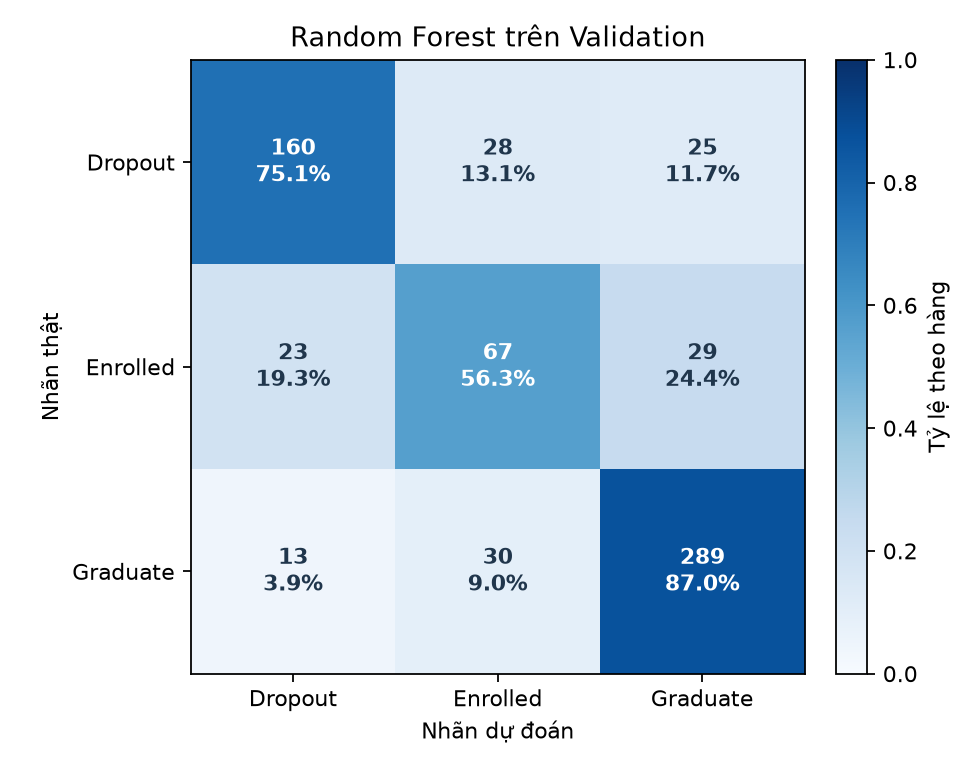

In [7]:
import matplotlib.pyplot as plt
from IPython.display import Image


def show_and_save(figure, filename):
    path = figure_dir / filename
    figure.tight_layout()
    figure.savefig(path, dpi=160, facecolor="white")
    plt.close(figure)
    display(Image(filename=str(path)))


# Màu thể hiện tỷ lệ trong mỗi lớp thật. Số in đậm là số sinh viên.
counts = confusion.to_numpy()
row_totals = counts.sum(axis=1, keepdims=True)
shares = np.divide(counts, row_totals, out=np.zeros_like(counts, dtype=float), where=row_totals != 0)
figure, ax = plt.subplots(figsize=(6.1, 4.8))
image = ax.imshow(shares, cmap="Blues", vmin=0, vmax=1)
for row in range(len(LABELS)):
    for column in range(len(LABELS)):
        ax.text(
            column, row, f"{counts[row, column]}\n{shares[row, column]:.1%}",
            ha="center", va="center", fontweight="bold",
            color="white" if shares[row, column] >= 0.55 else "#20364C",
        )
ax.set(
    xticks=range(len(LABELS)), yticks=range(len(LABELS)),
    xticklabels=LABELS, yticklabels=LABELS,
    xlabel="Nhãn dự đoán", ylabel="Nhãn thật", title="Random Forest trên Validation",
)
figure.colorbar(image, ax=ax, fraction=0.046, pad=0.04, label="Tỷ lệ theo hàng")
show_and_save(figure, "validation_confusion.png")

### Nhận xét

Random Forest đạt **Macro-F1 0,7293** trên 664 mẫu Validation, cao hơn 0,0355 điểm so với Logistic (**0,6938**). Dummy đạt **0,2222**.

- **Dropout.** RF nhận diện đúng **160/213** ca, tương ứng recall **75,12%**. Trong 53 ca bỏ sót, **28** bị dự đoán là Enrolled và **25** bị dự đoán là Graduate.
- **Enrolled.** Đây là lớp có F1 thấp nhất trong ba lớp. RF nhận ra **67/119** mẫu Enrolled. F1 lớp này đạt **0,5492**, so với **0,4915** của Logistic.
- **Accuracy và F2 Dropout.** RF dự đoán đúng **516/664** sinh viên (**77,71%**). F2 Dropout là **0,7634**.

## 5. Mô hình dựa vào đặc trưng nào?

*Permutation importance* xáo trộn từng cột trên Validation và đo Macro-F1 thay đổi bao nhiêu, giữ nguyên pipeline đã fit. Đưa 36 cột gốc vào pipeline để đo tác động của cả một biến như `Course`, thay vì tách riêng từng cột one-hot của biến đó. 

,feature,macro_f1_drop_mean,macro_f1_drop_std
0,Curricular units 2nd sem (approved),0.0897,0.0100
1,Tuition fees up to date,0.0456,0.0065
2,Curricular units 1st sem (approved),0.0299,0.0042
3,Curricular units 2nd sem (grade),0.0288,0.0038
4,Curricular units 2nd sem (evaluations),0.0225,0.0087
5,Curricular units 1st sem (evaluations),0.0153,0.0078
6,Course,0.0146,0.0061
7,Father's occupation,0.0128,0.0022
8,Curricular units 1st sem (grade),0.0128,0.0083
9,Inflation rate,0.0118,0.0053


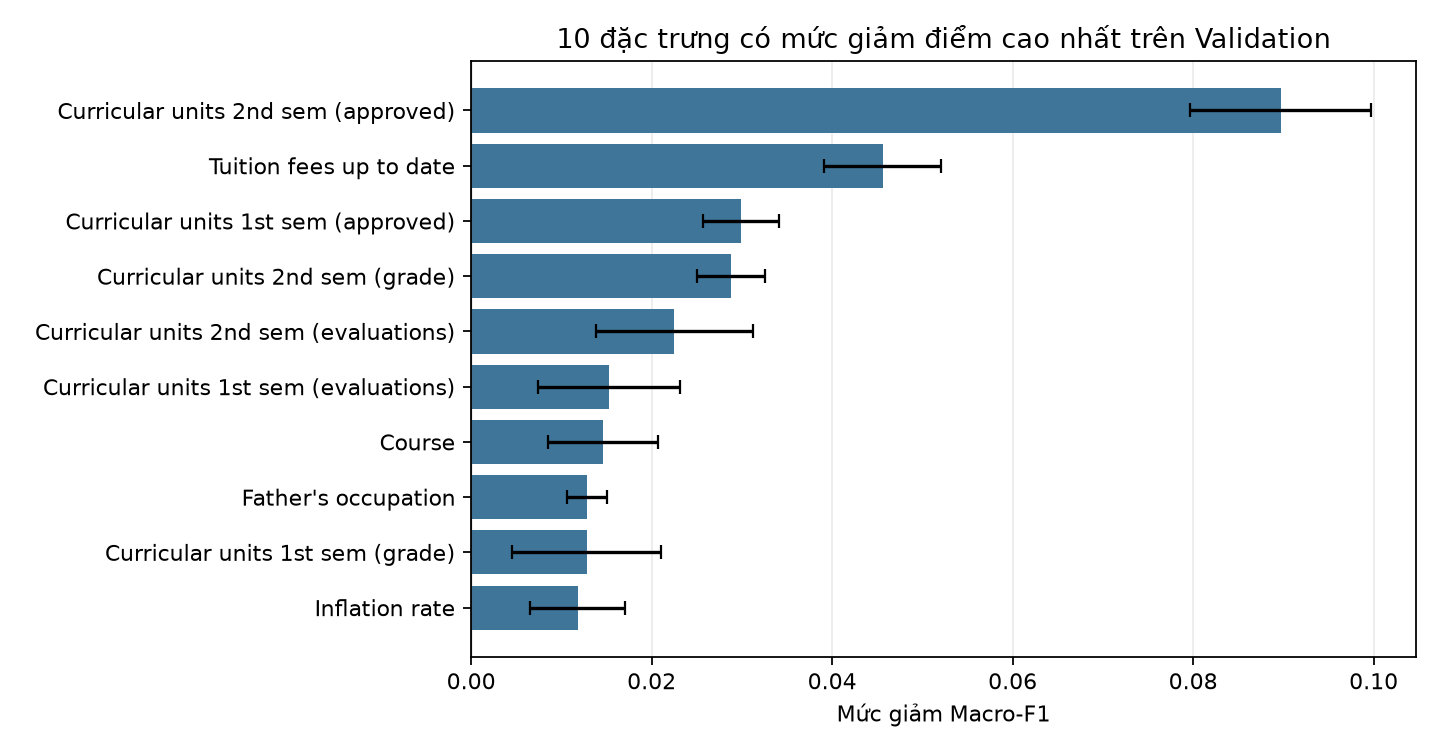

In [8]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score, make_scorer

# Dùng cùng định nghĩa Macro-F1 ba lớp như hàm metric của nhóm.
macro_f1 = make_scorer(f1_score, average="macro", labels=list(LABELS), zero_division=0)
n_repeats = 8
permutation = permutation_importance(
    best_pipeline, X_val, y_val, scoring=macro_f1,
    n_repeats=n_repeats, random_state=seed, n_jobs=1,
)
importance = pd.DataFrame({
    "feature": X_val.columns,
    "macro_f1_drop_mean": permutation.importances_mean,
    "macro_f1_drop_std": permutation.importances_std,
}).sort_values("macro_f1_drop_mean", ascending=False, ignore_index=True)
importance.to_csv(table_dir / "permutation_importance.csv", index=False)
display(importance.head(10).round(4))

# Thanh ngang biểu diễn độ giảm điểm trung bình. Vạch nhỏ là độ lệch chuẩn qua các lần xáo trộn.
top = importance.head(10).iloc[::-1]
figure, ax = plt.subplots(figsize=(9.0, 4.7))
ax.barh(top["feature"], top["macro_f1_drop_mean"], xerr=top["macro_f1_drop_std"],
        color="#3F7599", capsize=3)
ax.axvline(0, color="#56606B", linewidth=1)
ax.set(xlabel="Mức giảm Macro-F1", title="10 đặc trưng có mức giảm điểm cao nhất trên Validation")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
show_and_save(figure, "permutation_importance.png")

### Nhận xét

Sau 8 lần xáo trộn mỗi cột, ba cột dưới đây có mức giảm điểm trung bình cao nhất. Thanh ngang mảnh trong biểu đồ thể hiện độ lệch chuẩn giữa các lần xáo trộn.

- `Curricular units 2nd sem (approved)`: giảm **0,0897** Macro-F1 trung bình.
- `Tuition fees up to date`: giảm **0,0456** Macro-F1 trung bình.
- `Curricular units 1st sem (approved)`: giảm **0,0299** Macro-F1 trung bình.

Các mức giảm cho thấy RF dựa vào các cột này để dự đoán trên Validation. Phép đo chỉ đánh giá khả năng dự đoán của mô hình trên dữ liệu này. Muốn kết luận một yếu tố gây bỏ học cần thiết kế nghiên cứu nhân quả. Nếu nhiều cột chứa thông tin tương tự, xáo trộn một cột có thể chỉ làm điểm giảm ít vì mô hình vẫn dùng được các cột còn lại. Các đặc trưng học tập HK2 chỉ phù hợp với mốc dự đoán đã có thông tin của học kỳ đó.

## 6. Lưu pipeline và thông tin bàn giao

File `.joblib` chứa cả bộ tiền xử lý và RF. Nhánh tích hợp có thể nạp pipeline và đưa vào DataFrame có 36 cột như CSV đã bỏ khoảng trắng ở tên cột. File `.json` ghi lại cấu hình, phiên bản thư viện và mã nhận diện dữ liệu để đối chiếu.

In [9]:
import platform
from datetime import datetime, timezone

import joblib
import sklearn

pipeline_path = artifact_dir / "random_forest_pipeline.joblib"
joblib.dump(best_pipeline, pipeline_path, compress=3)

# Đọc lại file vừa lưu và kiểm tra hai pipeline cho cùng dự đoán trên Validation.
reloaded = joblib.load(pipeline_path)
if not np.array_equal(reloaded.predict(X_val), y_pred):
    raise ValueError("Pipeline nạp lại cho dự đoán khác pipeline vừa fit.")

metadata = {
    "model": "RandomForestClassifier",
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "notebook": "notebooks/models/random_forest/04_random_forest.ipynb",
    "python_version": platform.python_version(),
    "sklearn_version": sklearn.__version__,
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "joblib_version": joblib.__version__,
    "data_sha256": data_hash,
    "split_file_sha256": split_hash,
    "hash_line_endings": "lf",
    "split_seed": seed,
    "labels": list(LABELS),
    "n_features_in": len(FEATURE_COLUMNS),
    "n_features_after_preprocess": len(best_pipeline["preprocess"].get_feature_names_out()),
    "scale_numeric": False,
    "best_config": {**best_config, "max_features": "sqrt", "bootstrap": True, "random_state": seed},
    "cross_validation": {
        "n_folds": len(folds), "n_configs": len(grid), "config_id": best_id,
        "selection_metric": "macro_f1",
        "macro_f1_mean": float(best_cv["macro_f1_mean"]),
        "macro_f1_std": float(best_cv["macro_f1_std"]),
    },
    "validation_n_samples": len(val_rows),
    "validation": {metric: float(validation_result[metric]) for metric in metrics_to_save},
    "permutation_repeats": n_repeats,
}
metadata_path = pipeline_path.with_suffix(".json")
with metadata_path.open("w", encoding="utf-8", newline="\n") as output:
    json.dump(metadata, output, indent=2, ensure_ascii=False)
    output.write("\n")
print(f"Đã lưu và nạp lại được {pipeline_path.relative_to(root)}")
print(f"Thông tin lượt chạy: {metadata_path.relative_to(root)}")

Đã lưu và nạp lại được artifacts\random_forest_pipeline.joblib
Thông tin lượt chạy: artifacts\random_forest_pipeline.json
